In [1]:
import json
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

In [36]:
# Load JSON data
with open('/Users/tuliopolido/Downloads/recurrence_mobilenetv3_pamap_training_metrics_20250713_201531.json', 'r') as file:
    data = json.load(file)

In [37]:
# Extract data from JSON
train_metrics = data['train_metrics']
test_metrics = data['test_metrics']
constants = data['constants']
losses = data['train_losses']

# Convert the confusion matrix to a NumPy array
test_metrics['conf_matrix'] = np.array(test_metrics['conf_matrix'])  # Convert to np.array

In [38]:
# Function to plot metrics
def plot_loss(loss, y_min=None, y_max=None):
    plt.plot(loss)
    plt.grid()
    plt.title("Loss by epoch")
    plt.ylabel("Loss")
    plt.xlabel('Epoch')
    plt.show()

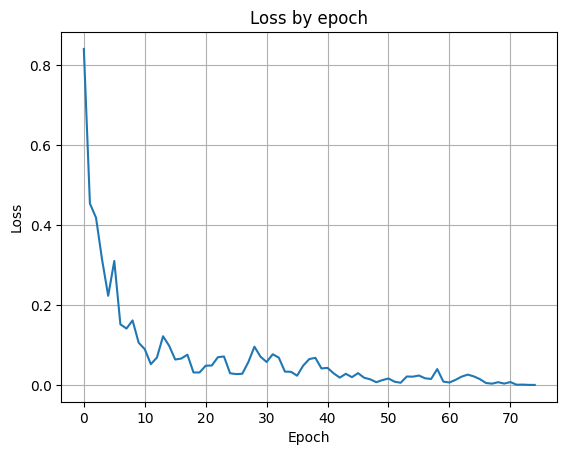

In [39]:
plot_loss(losses)

In [40]:
# Function to plot metrics
def plot_metrics(train, test, title, metric, y_min=None, y_max=None):
    plt.plot(train)
    plt.plot(test)
    plt.grid()
    plt.title(title)
    plt.ylabel(metric)
    plt.xlabel('Epoch')

    if y_min is not None and y_max is not None:
        plt.ylim(y_min, y_max)
        
    plt.legend(['Train', 'Validation'], loc='best')
    plt.show()

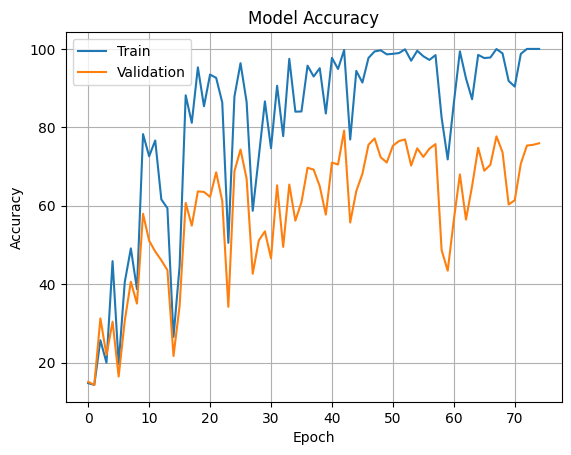

In [41]:
# Plot accuracy
plot_metrics(train_metrics['accuracy'], test_metrics['accuracy'], 'Model Accuracy', 'Accuracy')

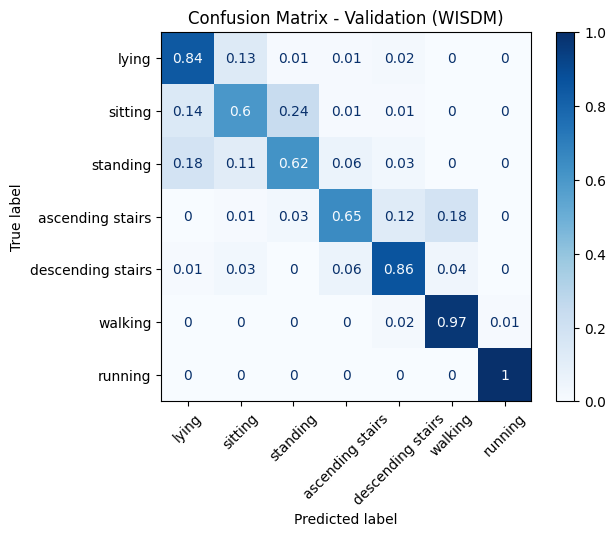

In [42]:
# Plot confusion matrix

disp = ConfusionMatrixDisplay(confusion_matrix=test_metrics['conf_matrix'].round(2), display_labels=constants['LABEL_NAMES'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Validation (WISDM)')
plt.xticks(rotation=45)
plt.show()